## **Modelo de Clasificación multiclase**

## **"Clasificación de la forma reportada en avistamientos de OVNIS en Estados Unidos mediante aprendizaje automático."**

Este notebook implementa un pipeline completo de preprocesamiento y aprendizaje automático (Machine Learning) para clasificar la forma reportada de un OVNI a partir de las características de cada avistamiento, mediante un modelo de clasificación multiclase supervisada.

Fuente de datos: NUFORC UFO Sightings - Data scraped from the National UFO reporting center – By Thaddeus Segura - (DbCL) v1.0

---

### Público destinatario y aplicación de los resultados

Este proyecto está orientado principalmente al ámbito académico, científico y tecnológico, especialmente a estudiantes, investigadores y profesionales interesados en la aplicación de técnicas de Ciencia de Datos e Inteligencia Artificial al análisis de reportes de fenómenos aéreos no identificados (OVNIs).

Mediante técnicas de aprendizaje automático supervisado, se busca identificar patrones en los registros históricos y evaluar la capacidad de distintos modelos para clasificar la forma reportada por los testigos.

Los resultados permiten explorar las relaciones entre las características geográficas, temporales y de duración de los avistamientos, y la categoría de forma informada (shape).

La finalidad es evaluar el potencial y las limitaciones de los modelos predictivos en este tipo de problemas de clasificación multiclase.

El modelo NO tiene como objetivo:

- Predecir cuándo ocurrirá un próximo avistamiento.
- Determinar dónde aparecerá un OVNI.
- Identificar visualmente un objeto.
- Determinar si un objeto es extraterrestre o explicar su origen.
- Verificar la veracidad de los testimonios.

El modelo SÍ busca:

- Clasificar la forma reportada por los testigos.
- Identificar patrones estadísticos en los registros históricos.
- Evaluar qué características contribuyen a la clasificación.


CARGA DE LIBRERIAS Y DATASET LIMPIO

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings('ignore')
import cufflinks as cf
import plotly.offline
cf.go_offline()
cf.set_config_file(offline=False, world_readable=True)

# Origen
url_csv = "https://github.com/arieltunon74/Aprendizaje_automatico_parcial_2026/raw/main/data/processed/dataset_procesado.csv"

print("Cargando el dataset procesado desde GitHub...")
df_procesado = pd.read_csv(url_csv, sep=';')
print("\n¡Dataset procesado cargado exitosamente!")
print(f"Total de registros (filas): {df_procesado.shape[0]:,}")
print(f"Total de columnas: {df_procesado.shape[1]}")

Cargando el dataset procesado desde GitHub...

¡Dataset procesado cargado exitosamente!
Total de registros (filas): 79,695
Total de columnas: 25


In [2]:
# Ver las primeras 10 filas del dataset
print("\n--- Primeras filas del dataset (.head()) ---")
display(df_procesado.head(10))


--- Primeras filas del dataset (.head()) ---


,occurred_date_time,city,state,shape,duration,posted_date,year,state_grouped,duration_seconds,occurred_datetime,...,Duracion_clasificacion,hour,time_of_day,is_weekend,shape_grouped,decade,us_region,posted_year,posted_month,posted_dayofweek
0,7/12/19 09:20,Redding,CA,Cylinder,5 minutes,2019-07-12,2019,CA,300,2019-07-12 09:20:00,...,Corto,9,Mañana,Día de semana,Other,2010s,West,2019,7,Friday
1,7/12/19 03:30,Charlotte,NC,Other,20 minutes,2019-07-12,2019,Other,1200,2019-07-12 03:30:00,...,Medio,3,Madrugada,Día de semana,Other,2010s,South,2019,7,Friday
2,7/11/19 22:40,Cedar Creek,TX,Other,20 seconds,2019-07-12,2019,TX,20,2019-07-11 22:40:00,...,Muy corto,22,Noche,Día de semana,Other,2010s,South,2019,7,Friday
3,7/11/19 22:10,San Bernardino,CA,Triangle,2 minutes,2019-07-12,2019,CA,120,2019-07-11 22:10:00,...,Corto,22,Noche,Día de semana,Triangle,2010s,West,2019,7,Friday
4,7/11/19 22:00,Bowling Green,KY,Other,45 minutes,2019-07-12,2019,Other,2700,2019-07-11 22:00:00,...,Largo,22,Noche,Día de semana,Other,2010s,South,2019,7,Friday
5,7/11/19 21:30,Dayton,NV,Circle,2 minutes,2019-07-12,2019,Other,120,2019-07-11 21:30:00,...,Corto,21,Noche,Día de semana,Circle,2010s,West,2019,7,Friday
6,7/11/19 20:25,Lakeland/Nashville border,GA,Changing,2 minutes,2019-07-12,2019,Other,120,2019-07-11 20:25:00,...,Corto,20,Noche,Día de semana,Other,2010s,South,2019,7,Friday
7,7/11/19 19:30,Pleasanton,CA,Light,5 minutes,2019-07-12,2019,CA,300,2019-07-11 19:30:00,...,Corto,19,Noche,Día de semana,Light,2010s,West,2019,7,Friday
8,7/11/19 05:15,Boise,ID,Circle,5 seconds,2019-07-12,2019,Other,5,2019-07-11 05:15:00,...,Muy corto,5,Madrugada,Día de semana,Circle,2010s,West,2019,7,Friday
9,7/11/19 02:50,Franklin-Alvadore,OR,Light,60 seconds,2019-07-12,2019,Other,60,2019-07-11 02:50:00,...,Muy corto,2,Madrugada,Día de semana,Light,2010s,West,2019,7,Friday


# **Análisis Exploratorio de Datos (EDA)**

Se analizan las distribuciones de las variables principales y otras correlaciones.

### DISTRIBUCIÓN DE LAS FORMAS DE OVNIS (shape) - ORIGINAL

28 (veintocho) clases - Formas más comunes: Los avistamientos de tipo Light (Luz), Circle (Círculo), Triangle (Triángulo), Fireball (Bola de fuego), Sphere (Esféra), Disc (Disco).

Clases con muy pocos registros: En el extremo inferior encontramos formas sumamente raras Diamond (Diamante), Pyramid (Pirámide) o Dome (Domo).

---

### DISTRIBUCIÓN DE LAS FORMAS DE OVNIS (shape_grouped) - CATEGORÍA DE FORMAS AGRUPADA

7 (siete) clases - Formas más comunes: Los avistamientos de tipo Other (Otros - conjunto de formas minoritarias) Light (Luz), Circle (Círculo), Triangle (Triángulo), Fireball (Bola de fuego), Sphere (Esféra), Disc (Disco).

---

### Fundamentación de la reducción de categorías de la variable objetivo (shape) para aplicar en la Agrupación (`shape_grouped`) de 28 clases a 7 clases para luego ser tomado como **variable objetivo del modelo**.

La reducción del número de categorías de la variable objetivo shape se plantea como una estrategia metodológica para abordar la complejidad del problema de clasificación multiclase.

Esta decisión toma como referencia el trabajo Improving Performance of Multiclass Classification by Inducing Class Hierarchies (2017), que estudia la organización jerárquica de categorías para simplificar los problemas de clasificación con múltiples clases, considerando las relaciones y confusiones entre ellas.

Sus autores proponen organizar las clases mediante jerarquías, reduciendo el número de categorías que intervienen en cada subproblema de clasificación.

Fuente: Science Direct
https://www.sciencedirect.com/science/article/pii/S1877050917308244?via%3Dihub

- Publicación: Procedia Computer Science, volumen 108, páginas 1692–1701.

---

La transformación de la variable objetivo original `shape` en un conjunto reducido de categorías consolidadas bajo la etiqueta **`shape_grouped`** responde a criterios tanto algorítmicos como inherentes al estudio de fenómenos aéreos no identificados (OVNI/UAP):

1. **Mitigación de la alta cardinalidad y clases minoritarias:**
   El análisis exploratorio reveló una marcada distribución de "cola larga", con decenas de formas marginales que presentaban frecuencias anecdóticas (ej. categorías con 1 o pocos registros, como *Dome, Flare, pyramid* o variaciones tipográficas). Mantener estas clases dispersas genera escasez de datos, impide una partición equilibrada entre entrenamiento y test, e induce un sobreajuste (*overfitting*)

2. **Tratamiento de la subjetividad y percepción del testigo:**
   En la casuística ufológica, la descripción morfológica está fuertemente condicionada por factores subjetivos y ambientales (distancia, ángulo de observación, condiciones lumínicas y agudeza visual). Un mismo evento puede ser interpretado y nombrado de forma distinta por diferentes testigos. Las categorías ultraespecíficas suelen reflejar variaciones semánticas o vocabulario individual más que diferencias físicas estructurales genuinas.

3. **Inconsistencia en los registros históricos y estandarización:**
   Las bases de datos de avistamientos recopilan reportes históricos donde los campos de texto libre o la ausencia de formularios estandarizados iniciales permitieron la proliferación de términos redundantes o aislados. Por eso se decide agruparlos en "other"

4. **Enfoque en las tipologías fenoménicas principales:**
   La literatura ufológica y estadística concuerda en que la gran mayoría de los reportes fiables se concentran en morfologías recurrentes y bien delimitadas (como luces nocturnas, esferas, triángulos, discos o círculos). Consolidar la variable objetivo permite que el modelo de aprendizaje automático supervise la clasificación centrándose en los patrones estructurales verdaderamente representativos del fenómeno estudiado, optimizando las métricas de evaluación global y la interpretabilidad de la matriz de confusión.


 Esta reducción de clases trae consecuencias para el modelo transformando un problema de clasificación inviable o altamente propenso al error por alta cardinalidad y datos insuficientes en un problema interpretable y estadísticamente viable. Si bien se sacrifica la capacidad de detectar rarezas extremas de la "Egg", "Cone" o "Cross"...se gana solidez en la identificación de los patrones principales del fenómeno estudiado.



========== ANÁLISIS COMPARATIVO: SHAPE VS SHAPE_GROUPED ==========
Cantidad de variables del dataset: 25
Clases shape original: 28 | Clases shape_grouped: 7


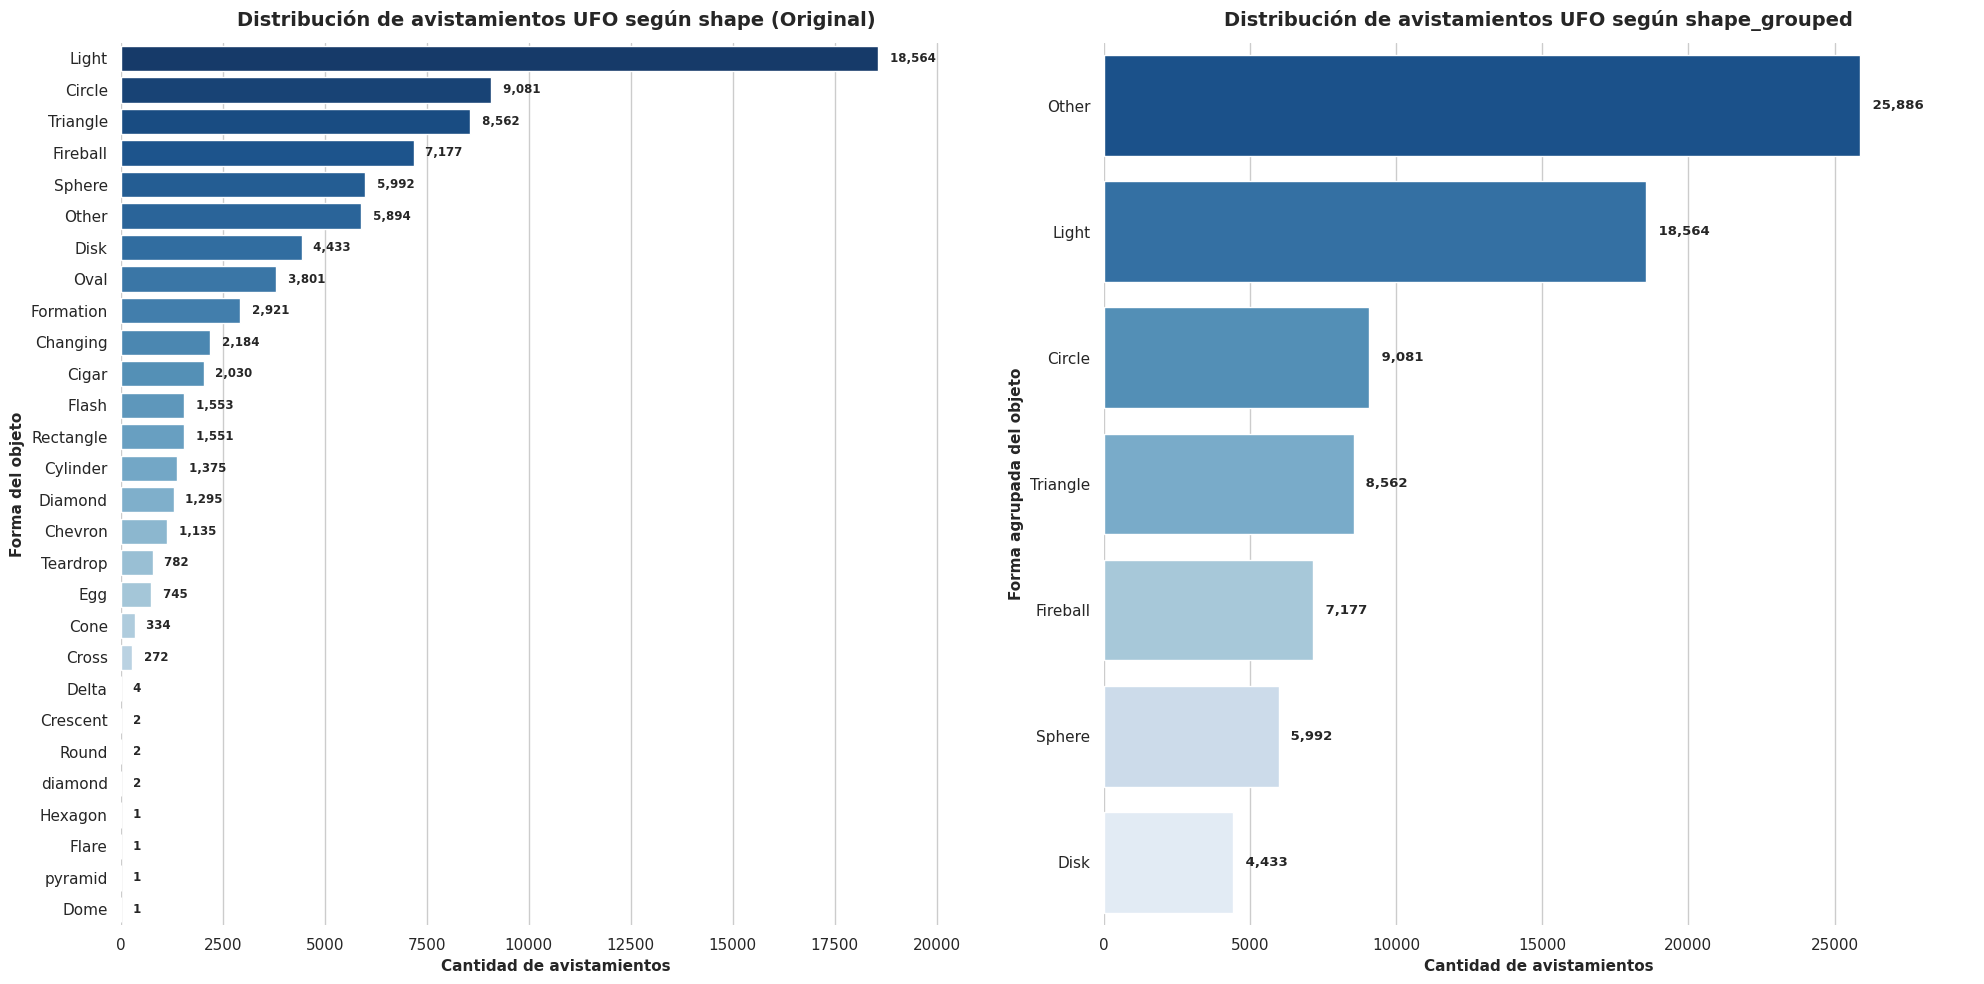

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
print("========== ANÁLISIS COMPARATIVO: SHAPE VS SHAPE_GROUPED ==========")
print(f"Cantidad de variables del dataset: {len(df_procesado.columns)}")
print(
    f"Clases shape original: {df_procesado['shape'].nunique()} | Clases shape_grouped: {df_procesado['shape_grouped'].nunique()}"
)
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# GRÁFICO 1: Shape Original (Izquierda)
frecuencias = df_procesado["shape"].value_counts()
sns.barplot(
    x=frecuencias.values,
    y=frecuencias.index,
    ax=axes[0],
    palette="Blues_r",
    hue=frecuencias.index,
    legend=False,
)

axes[0].set_title(
    "Distribución de avistamientos UFO según shape (Original)",
    fontsize=14,
    fontweight="bold",
    pad=12,
)
axes[0].set_xlabel("Cantidad de avistamientos", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Forma del objeto", fontsize=11, fontweight="bold")

max_orig = frecuencias.values.max()
axes[0].set_xlim(0, max_orig * 1.15)
for i, valor in enumerate(frecuencias.values):
  axes[0].text(
      valor + (max_orig * 0.01),
      i,
      f" {valor:,}",
      va="center",
      ha="left",
      fontsize=8.5,
      fontweight="semibold",
  )

# GRÁFICO 2: Shape Grouped (Derecha)
frecuencias_grouped = df_procesado["shape_grouped"].value_counts()
sns.barplot(
    x=frecuencias_grouped.values,
    y=frecuencias_grouped.index,
    ax=axes[1],
    palette="Blues_r",
    hue=frecuencias_grouped.index,
    legend=False,
)

axes[1].set_title(
    "Distribución de avistamientos UFO según shape_grouped",
    fontsize=14,
    fontweight="bold",
    pad=12,
)
axes[1].set_xlabel("Cantidad de avistamientos", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Forma agrupada del objeto", fontsize=11, fontweight="bold")

max_group = frecuencias_grouped.values.max()
axes[1].set_xlim(0, max_group * 1.15)

for i, valor in enumerate(frecuencias_grouped.values):
  axes[1].text(
      valor + (max_group * 0.01),
      i,
      f" {valor:,}",
      va="center",
      ha="left",
      fontsize=9.5,
      fontweight="bold",
  )

sns.despine(ax=axes[0], left=True, bottom=True)
sns.despine(ax=axes[1], left=True, bottom=True)
plt.tight_layout()
plt.show()

## GRÁFICO 2 - ANÁLISIS DE LA DISTRIBUCIÓN GEOGRÁFICA DE LOS AVISTAMIENTOS OVNI EN EE.UU

### **Cantidad de avistamientos de OVNIs reportados según la región geográfica de los Estados Unidos - Variable predictora: (`us_region`).**

El análisis de la distribución geográfica permite comprender cómo se encuentran representados los reportes de avistamientos de OVNIs en Estados Unidos, tanto a nivel regional como estatal.

Los resultados muestran una distribución desigual de los registros, con una mayor concentración en las regiones West y South, y una destacada participación del estado de California.

Es importante señalar que la cantidad de reportes no representa necesariamente una mayor incidencia real de avistamientos, ya que también puede estar influenciada por factores como la población, la distribución de los habitantes y la predisposición a reportar estos fenómenos.

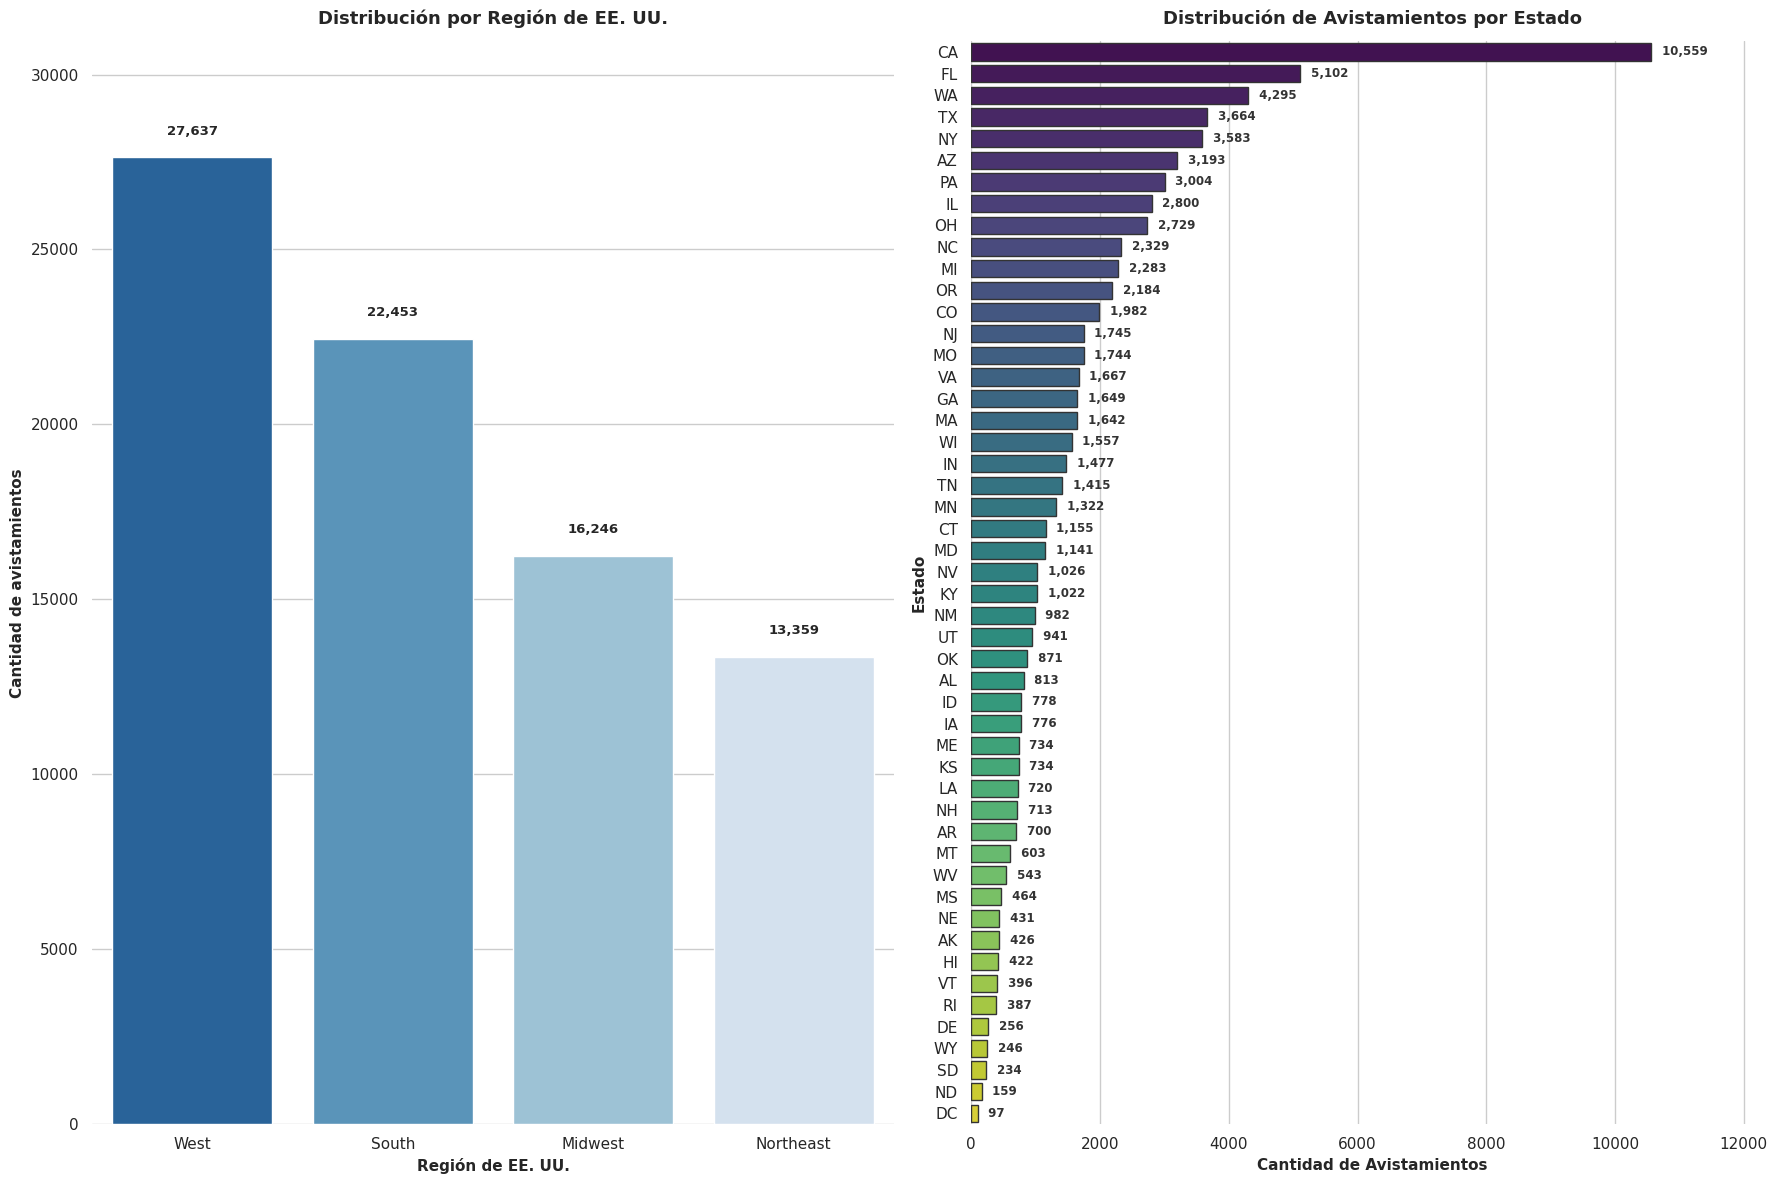

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 12))

# GRÁFICO 1: Distribución por Región (Izquierda)

frecuencias_region = df_procesado["us_region"].value_counts()

sns.barplot(
    x=frecuencias_region.index,
    y=frecuencias_region.values,
    ax=axes[0],
    palette="Blues_r",
    hue=frecuencias_region.index,
    legend=False,
)

axes[0].set_title(
    "Distribución por Región de EE. UU.", fontsize=13, fontweight="bold", pad=12
)
axes[0].set_xlabel("Región de EE. UU.", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Cantidad de avistamientos", fontsize=11, fontweight="bold")
max_reg = frecuencias_region.values.max()
axes[0].set_ylim(0, max_reg * 1.12)
for i, valor in enumerate(frecuencias_region.values):
  axes[0].text(
      i,
      valor + (max_reg * 0.02),
      f"{valor:,}",
      ha="center",
      va="bottom",
      fontsize=9.5,
      fontweight="bold",
  )

# GRÁFICO 2: Distribución por Estado (Derecha)

frecuencias_state = (
    df_procesado["state"]
    .astype(str)
    .str.strip()
    .str.upper()
    .value_counts()
    .sort_values(ascending=False)
)

sns.barplot(
    x=frecuencias_state.values,
    y=frecuencias_state.index,
    ax=axes[1],
    hue=frecuencias_state.index,
    palette="viridis",
    legend=False,
    edgecolor=".2",
)

axes[1].set_title(
    "Distribución de Avistamientos por Estado",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
axes[1].set_xlabel(
    "Cantidad de Avistamientos", fontsize=11, fontweight="bold"
)
axes[1].set_ylabel("Estado", fontsize=11, fontweight="bold")

max_state = frecuencias_state.values.max()
axes[1].set_xlim(0, max_state * 1.18)
for i, valor in enumerate(frecuencias_state.values):
  axes[1].text(
      valor + (max_state * 0.01),
      i,
      f" {valor:,}",
      va="center",
      ha="left",
      fontsize=8.5,
      fontweight="semibold",
      color="#333333",
  )
sns.despine(ax=axes[0], left=True, bottom=True)
sns.despine(ax=axes[1], left=True, bottom=True)
plt.tight_layout()
plt.show()

## ANÁLISIS DE LAS DISTRIBUCIONES TEMPORALES DE LOS AVISTAMIENTOS OVNI

* **Estacionalidad (`north_season`):** Permite identificar en qué épocas del año (verano, invierno, etc.) ocurren más reportes. Se observa una concentración superior de avistamientos durante los meses de verano y otoño, lo cual suele correlacionarse con mayores actividades al aire libre, mejores condiciones climáticas para la observación nocturna y períodos vacacionales de los testigos.

* **Momento del día (`time_of_day`):** Ayuda a ver si predominan los avistamientos nocturnos frente a los diurnos.
La inmensa mayoría de los reportes se concentran en el período nocturno. Esto se debe a factores lógicos de visibilidad que contrastan de manera más evidente contra el cielo oscuro.

* **Patrones temporales (`decade` / `day_category` / `is_weekend`):** Muestran la evolución histórica por décadas y si hay tendencias según el tipo de día.
Además según los registros, se observa que el incremento de avistamientos durante los fines de semana (especialmente viernes y sábados) responde a la disponibilidad de tiempo libre de la población y a una mayor propensión a la observación del cielo en contextos recreativos o de descanso.
`decade`: A lo largo del tiempo, con un pico masivo en las décadas de los 2000s y 2010s. Este comportamiento no necesariamente implica un aumento físico de los avistamientos, sino una mayor digitalización, acceso a internet, difusión masiva de plataformas de reporte y estandarización de formularios de avistamiento en los últimos años.

* **Duración (`Duracion_clasificacion`):** Agrupa los eventos según cuánto tiempo duraron reportados. Sugiere que la mayoría de los fenómenos se manifiestan como destellos, tránsitos rápidos o destellos transitorios más que como eventos estáticos prolongados.


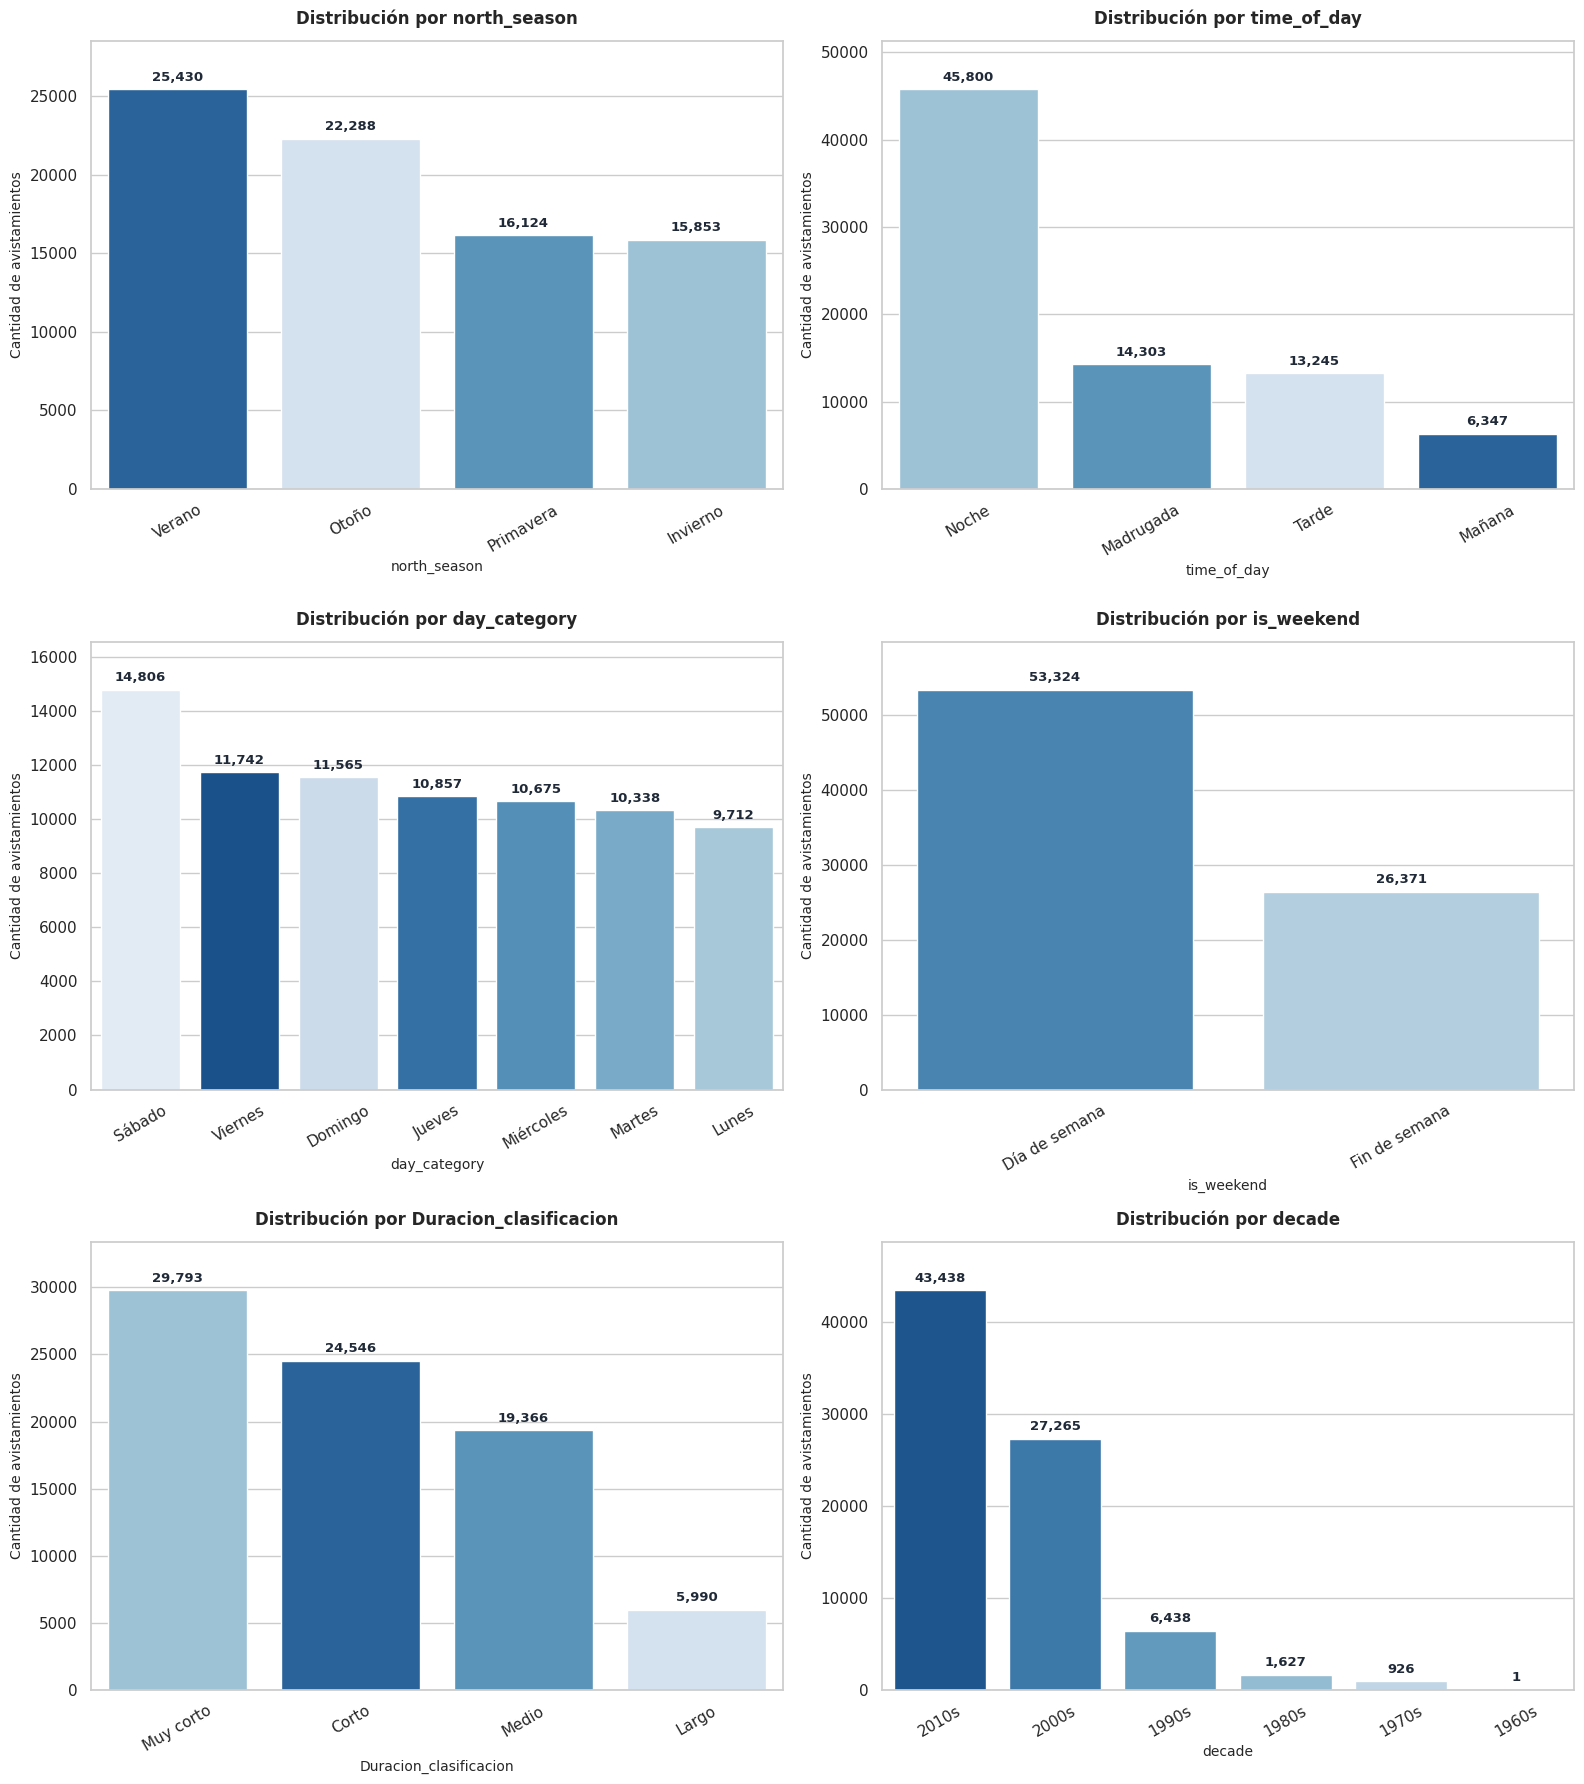

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

# Lista de variables a graficar
variables = [
    "north_season",
    "time_of_day",
    "day_category",
    "is_weekend",
    "Duracion_clasificacion",
    "decade",
]
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()
for i, var in enumerate(variables):
  if var in df_procesado.columns:
    order = df_procesado[var].value_counts().index

    sns.countplot(
        data=df_procesado,
        x=var,
        ax=axes[i],
        palette="Blues_r",
        order=order,
        hue=var,
        legend=False,
    )
    max_height = max([p.get_height() for p in axes[i].patches])
    axes[i].set_ylim(0, max_height * 1.12)
    for p in axes[i].patches:
      height = p.get_height()
      if height > 0:
        axes[i].annotate(
            f"{int(height):,}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            xytext=(0, 4),
            textcoords="offset points",
            fontweight="bold",
            fontsize=9.5,
            color="#1f2937",
        )

    axes[i].set_title(
        f"Distribución por {var}", fontsize=12, fontweight="bold", pad=12
    )
    axes[i].set_xlabel(var, fontsize=10)
    axes[i].set_ylabel("Cantidad de avistamientos", fontsize=10)
    axes[i].tick_params(axis="x", rotation=30)
  else:
    axes[i].set_visible(False)
    print(f"Advertencia: La columna '{var}' no se encuentra en el DataFrame.")
plt.tight_layout()
plt.show()


# Preparar features y targets

Target (Variable Objetivo - y)
shape_grouped: Es la forma del objeto volador agrupada en categorías consolidadas (7 clases), que el modelo debe predecir.

Features (Variables Predictoras - X)
Se utilizan 13 características en total, organizadas según su tipo de dato y transformación:

### Numéricas (5):

duration_seconds: Duración del avistamiento expresada en segundos.

year: Año en que ocurrió el evento.

month: Mes del avistamiento.

day_of_week: Día de la semana (valor numérico).

hour: Hora del día del reporte.

### Categóricas Ordinales (2):

Duracion_clasificacion: Rango categórico ordenado de duración (Muy corto, Corto, Medio, Largo).

decade: Década histórica ordenada (1960s a 2010s).

### Categóricas Nominales (6):

state_grouped: Estado de EE. UU. donde ocurrió el avistamiento (agrupado).

us_region: Región geográfica de EE. UU. (West, South, Midwest, Northeast).

north_season: Estación del año correspondiente al hemisferio norte.

time_of_day: Momento del día (Noche, Madrugada, Tarde, Mañana).

day_category: Nombre o categoría del día de la semana.

is_weekend: Indicador booleano de si el reporte ocurrió en fin de semana.


# Estrategia de preprocesamiento y preparación de datos


1. Estratificación (stratify=y): Mantiene la proporción de las clases de shape_grouped en los conjuntos de entrenamiento y prueba, evitando una representación desigual de las categorías.

2. Tratamiento diferenciado de variables:
- Numéricas: imputación por mediana y estandarización con StandardScaler.
- Ordinales: codificación con OrdinalEncoder, respetando el orden jerárquico de las categorías.
- Nominales: codificación con OneHotEncoder, permitiendo manejar categorías desconocidas.
3. Valores faltantes: Se utilizan SimpleImputer dentro de cada sub-pipeline para gestionar los valores nulos y garantizar la continuidad del procesamiento.



Target ($y$):

shape_grouped

---

Variables de Entrada Seleccionadas ($X$):

Numéricas: duration_seconds, year, month', day_of_week, hour`Categóricas: state_grouped, us_region, north_season, time_of_day, day_category, is_weekend, Duracion_clasificacion, decade

# MODELADO

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

def preparar_datos_ml(ruta_csv='https://github.com/arieltunon74/Aprendizaje_automatico_parcial_2026/raw/main/data/processed/dataset_procesado.csv'):
    # 1. Cargar el dataset
    df = pd.read_csv(ruta_csv, sep=';')

    # 2. Definir la variable objetivo y las características limpias (sin shape, duration ni leakage)
    target = 'shape_grouped'

    features = [
        # Variables numéricas
        'duration_seconds', 'year', 'month', 'day_of_week', 'hour',
        # Variables categóricas / temporales / geográficas seguras
        'state_grouped', 'us_region', 'north_season', 'time_of_day',
        'day_category', 'is_weekend', 'Duracion_clasificacion', 'decade'
    ]

    X = df[features]
    y = df[target]

    # 3. División estricta Train/Test con estratificación (Previene Data Leakage global)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # 4. Definición de subgrupos de columnas según su naturaleza
    numerical_cols = ['duration_seconds', 'year', 'month', 'day_of_week', 'hour']

    ordinal_cols = ['Duracion_clasificacion', 'decade']
    categories_order = [
        ['Muy corto', 'Corto', 'Medio', 'Largo'],                # Orden para Duracion_clasificacion
        ['1960s', '1970s', '1980s', '1990s', '2000s', '2010s']     # Orden para decade
    ]

    nominal_cols = [
        'state_grouped', 'us_region', 'north_season',
        'time_of_day', 'day_category', 'is_weekend'
    ]

    # 5. Construcción de sub-pipelines independientes (imputación ajustada solo en train)
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    ordinal_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder(
            categories=categories_order,
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ])

    nominal_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    # 6. Integración en un ColumnTransformer global
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numerical_cols),
            ('ord', ordinal_transformer, ordinal_cols),
            ('cat', nominal_transformer, nominal_cols)
        ]
    )

    # 7. Ajuste seguro: fit_transform exclusivamente en Train, transform en Test
    X_train_processed = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)

    print("=== Proceso Finalizado con Éxito ===")
    print(f"Dimensiones X_train procesado: {X_train_processed.shape}")
    print(f"Dimensiones X_test procesado:  {X_test_processed.shape}")
    print(f"Dimensiones y_train:           {y_train.shape}")
    print(f"Dimensiones y_test:            {y_test.shape}")

    return X_train_processed, X_test_processed, y_train, y_test, preprocessor

# Ejecutar la función si se corre el script directamente
if __name__ == '__main__':
    X_train_p, X_test_p, y_train, y_test, preprocessor_fitted = preparar_datos_ml()

=== Proceso Finalizado con Éxito ===
Dimensiones X_train procesado: (63756, 38)
Dimensiones X_test procesado:  (15939, 38)
Dimensiones y_train:           (63756,)
Dimensiones y_test:            (15939,)


## MODELO IMPLEMENTADO: RANDOM FOREST

### Se realizaron pruebas con otros diferentes modelos de aprendizaje automático supervisado como Regresión Logística Multinomial, Arboles de decisión y KNN; tanto para las 27 variables de shape como para las 7 de shape_grouped, pero no se obtuvieron resultados significativos, es decir que estos modelos probados presentaron un desempeño inferior según las métricas de evaluación.

### El modelo que mejor se adaptó fue Random Forest, fue seleccionado por presentar el mejor desempeño relativo, no porque necesariamente sea el mejor algoritmo para cualquier problema de clasificación.

Accuracy de Random Forest (con balanceo): 0.2111173850304285

Reporte de Clasificación:
               precision    recall  f1-score   support

      Circle       0.15      0.12      0.14      1816
        Disk       0.12      0.25      0.16       887
    Fireball       0.18      0.53      0.27      1435
       Light       0.31      0.22      0.25      3713
       Other       0.40      0.15      0.22      5177
      Sphere       0.10      0.07      0.08      1198
    Triangle       0.17      0.30      0.21      1713

    accuracy                           0.21     15939
   macro avg       0.20      0.23      0.19     15939
weighted avg       0.27      0.21      0.21     15939



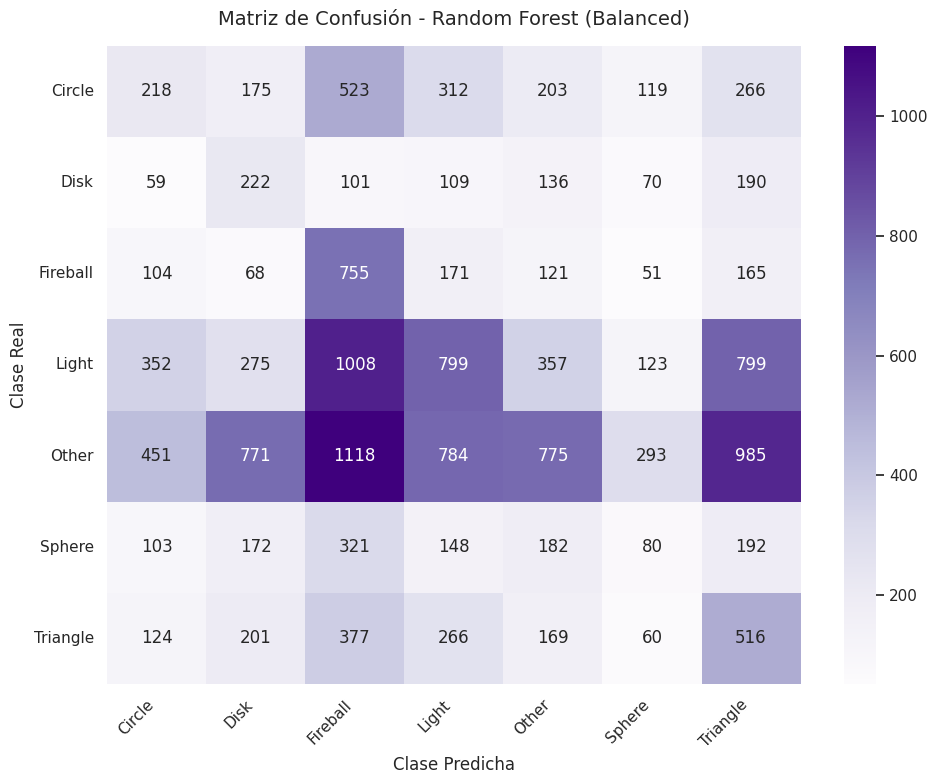

In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar el dataset desde la URL de GitHub para evitar FileNotFoundError
url_csv = "https://github.com/arieltunon74/Aprendizaje_automatico_parcial_2026/raw/main/data/processed/dataset_procesado.csv"
df = pd.read_csv(url_csv, sep=';')

target = 'shape_grouped'
features = [
    'duration_seconds', 'year', 'month', 'day_of_week', 'hour',
    'state_grouped', 'us_region', 'north_season', 'time_of_day',
    'day_category', 'is_weekend', 'Duracion_clasificacion', 'decade'
]

X = df[features]
y = df[target]

# 2. División estricta Train/Test (Previene Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Definición de columnas
numerical_cols = ['duration_seconds', 'year', 'month', 'day_of_week', 'hour']
ordinal_cols = ['Duracion_clasificacion', 'decade']
categories_order = [
    ['Muy corto', 'Corto', 'Medio', 'Largo'],
    ['1960s', '1970s', '1980s', '1990s', '2000s', '2010s']
]
nominal_cols = ['state_grouped', 'us_region', 'north_season', 'time_of_day', 'day_category', 'is_weekend']

# 4. Pipelines de transformación interna (Imputación y codificación segura)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=categories_order, handle_unknown='use_encoded_value', unknown_value=-1))
])

nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('ord', ordinal_transformer, ordinal_cols),
        ('cat', nominal_transformer, nominal_cols)
    ]
)

# 5. Pipeline Integrado con Random Forest Classifier aplicando class_weight='balanced'
model_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# 6. Ajustar (Train) y Predecir (Test)
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)
y_proba_rf = model_rf.predict_proba(X_test)

print("Accuracy de Random Forest (con balanceo):", accuracy_score(y_test, y_pred_rf))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred_rf, zero_division=0))


# 7. Matriz de Confusión
labels = model_rf.named_steps['classifier'].classes_
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Purples', xticklabels=labels, yticklabels=labels)
plt.title('Matriz de Confusión - Random Forest (Balanced)', fontsize=14, pad=15)
plt.xlabel('Clase Predicha', fontsize=12)
plt.ylabel('Clase Real', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('matriz_confusion_rf.png', dpi=300)
plt.show()

### RESULTADOS DE LA MATRIZ DE CONFUSIÓN:

| Categoría | Predicciones Correctas (Aciertos) | Observaciones y Comportamiento |
| :--- | :---: | :--- |
| **Fireball** | 755 | Categoría con mejor reconocimiento del modelo. |
| **Triangle** | 516 | Sólido rendimiento en la clasificación estructural. |
| **Disk** | 222 | Desempeño moderado. |
| **Sphere** | 80 | Dificultades críticas de reconocimiento. |
| **Other / Light** | - | Elevada tasa de confusión cruzada (especialmente con Fireball y Triangle). |

**El modelo encuentra dificultades para distinguir determinadas formas a partir de las características disponibles.**

---

### **Resultados de las métricas por categoría**

A partir de los valores de tu matriz de confusión, se pueden calcular las siguientes métricas:

Resultados calculados sobre 15.939 registros de prueba.

| Categoría | Precision | Recall | F1-score |
| :--- | :---: | :---: | :---: |
| **Circle** | 15,45 % | 12,00 % | 14,00 % |
| **Disk** | 12,00 % | 25,00 % | 16,00 % |
| **Fireball** | 18,00 % | 53,00 % | 27,00 % |
| **Light** | 31,00 % | 22,00 % | 25,00 % |
| **Other** | 40,00 % | 15,00 % | 22,00 % |
| **Sphere** | 10,00 % | 7,00 % | 8,00 % |
| **Triangle** | 17,00 % | 30,00 % | 21,00 % |

Estos resultados indican que el modelo presenta problemas para distinguir determinadas categorías, posiblemente relacionados con la similitud entre las características de los reportes, la heterogeneidad de los registros y el desequilibrio en la distribución de las clases.

Fireball obtuvo el mayor recall (53 %), aunque con una precisión del 18 %. Por su parte, Other alcanzó la mayor precisión (40 %), pero un recall del 15 %. Sphere presentó los menores valores de recall y F1-score de la tabla. Estos resultados muestran que ninguna categoría alcanzó simultáneamente valores elevados de precisión y sensibilidad.

Desde una perspectiva académica y de investigación, este análisis permite evaluar las capacidades y limitaciones de los algoritmos de aprendizaje automático aplicados al estudio de reportes históricos de fenómenos aéreos no identificados.

Se concluye que Random Forest con balanceo de clases es un punto de referencia experimental para futuras investigaciones, sin que los resultados obtenidos permitan considerarlo una solución predictiva satisfactoria para el objetivo planteado. Hasta aquí llega el alcance del proyecto.

### VISUALIZACIÓN DE LAS MÉTRICAS OBTENIDAS - Precision, Recall y F1-score

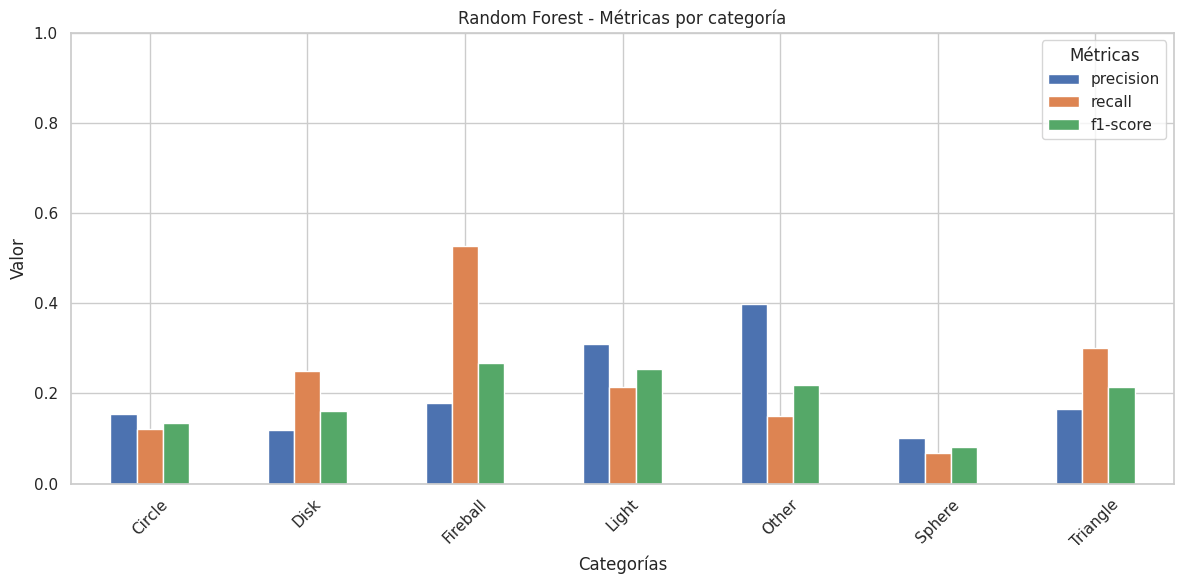

In [8]:
from sklearn.metrics import classification_report

reporte = classification_report(
    y_test,
    y_pred_rf,
    output_dict=True,
    zero_division=0
)

metricas = pd.DataFrame(reporte).T

metricas = metricas.loc[
    model_rf.classes_,
    ['precision', 'recall', 'f1-score']
]

metricas.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Random Forest - Métricas por categoría')
plt.ylabel('Valor')
plt.xlabel('Categorías')
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.legend(title='Métricas')
plt.tight_layout()
plt.show()

## Importancia de las variables predictoras utilizadas para el modelo Random Forest

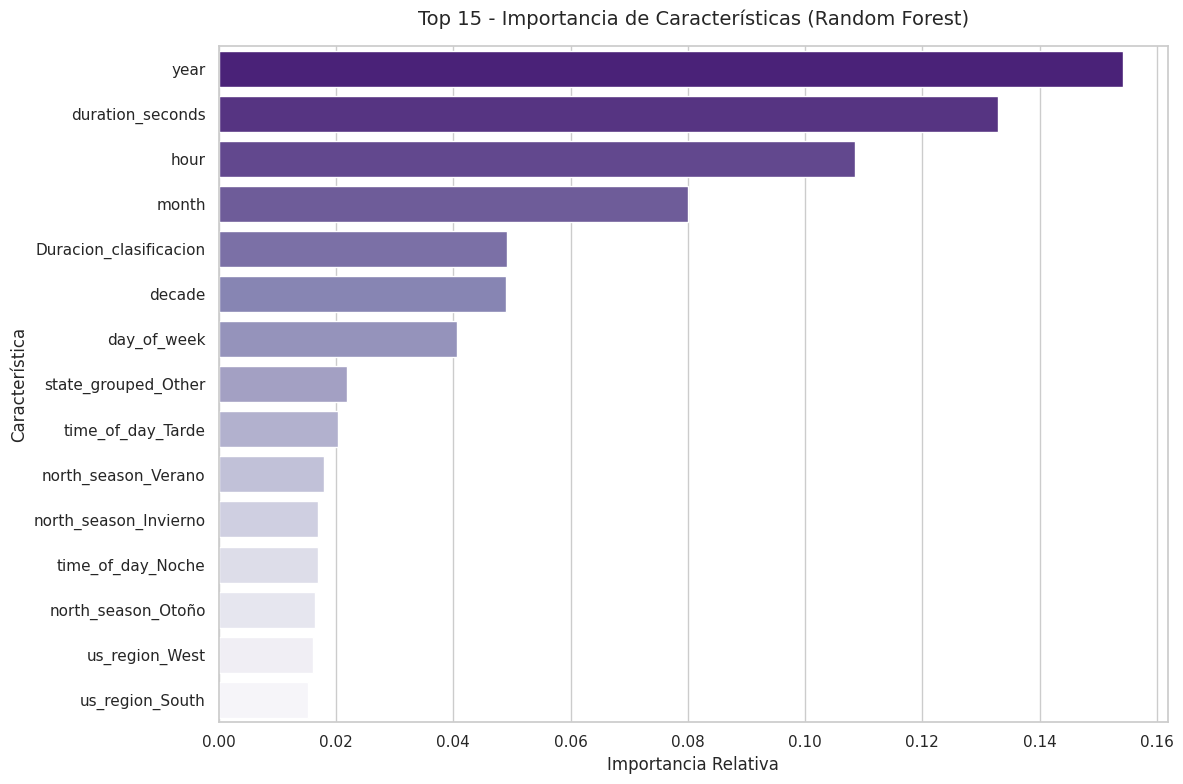

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Extraer los nombres de las características después de la transformación (OneHotEncoder)
ohe_feature_names = model_rf.named_steps['preprocessor'] \
    .named_transformers_['cat'] \
    .named_steps['onehot'] \
    .get_feature_names_out(nominal_cols)

# Combinar todas las características (numéricas + ordinales + nominales codificadas)
all_feature_names = numerical_cols + ordinal_cols + list(ohe_feature_names)

# 2. Obtener los valores de importancia del modelo Random Forest
importances = model_rf.named_steps['classifier'].feature_importances_

# 3. Crear un DataFrame para ordenar las características de mayor a menor importancia
df_importances = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 4. Graficar el Top 15 de características más importantes
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Importance',
    y='Feature',
    data=df_importances.head(15),
    palette='Purples_r'
)
plt.title('Top 15 - Importancia de Características (Random Forest)', fontsize=14, pad=15)
plt.xlabel('Importancia Relativa', fontsize=12)
plt.ylabel('Característica', fontsize=12)
plt.tight_layout()
plt.savefig('importancia_caracteristicas_rf.png', dpi=300)
plt.show()

## Esquema de RANDOM FOREST implementado

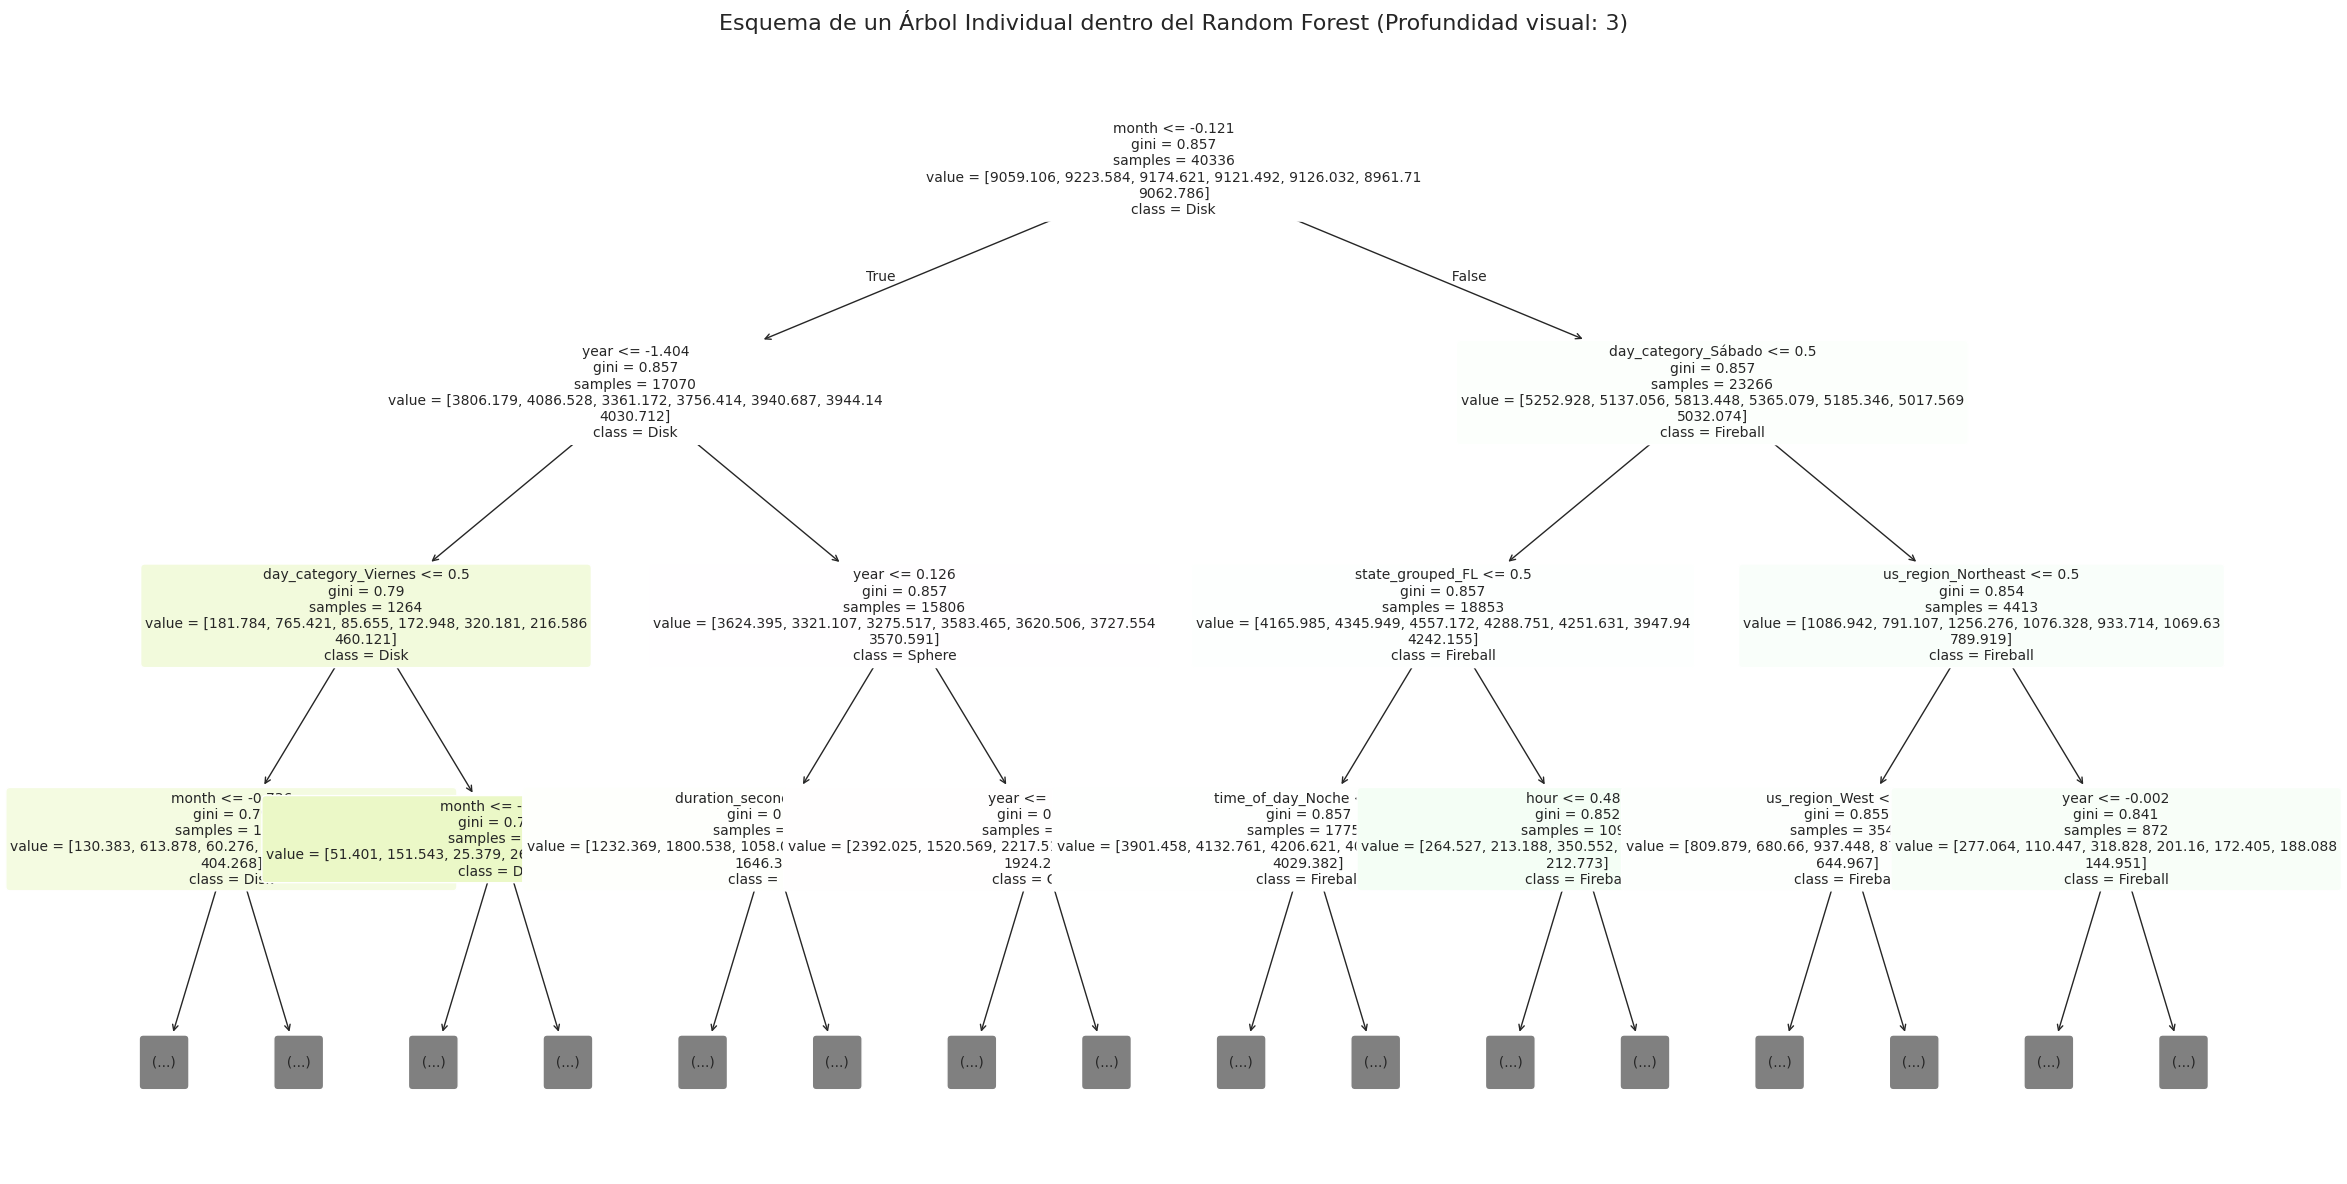

In [10]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# 1. Extraer el primer árbol del Random Forest entrenado
# (puedes cambiar el índice [0] por cualquier otro número entre 0 y 99)
single_tree = model_rf.named_steps['classifier'].estimators_[0]

# 2. Reconstruir la lista completa de nombres de características después del preprocesamiento
ohe_feature_names = model_rf.named_steps['preprocessor'] \
    .named_transformers_['cat'] \
    .named_steps['onehot'] \
    .get_feature_names_out(nominal_cols)

all_feature_names = list(numerical_cols) + list(ordinal_cols) + list(ohe_feature_names)

# 3. Generar el gráfico del árbol de decisión
plt.figure(figsize=(24, 12))
plot_tree(
    single_tree,
    feature_names=all_feature_names,
    class_names=[str(c) for c in model_rf.named_steps['classifier'].classes_],
    filled=True,
    rounded=True,
    max_depth=3,  # Limitamos la profundidad visual a 3 niveles para que sea legible (puedes aumentarlo o quitarlo)
    fontsize=10
)

plt.title('Esquema de un Árbol Individual dentro del Random Forest (Profundidad visual: 3)', fontsize=16, pad=20)
plt.tight_layout()
plt.savefig('arbol_individual_rf.png', dpi=300)
plt.show()

### Visualización de la Curva ROC multiclase

Aprendizaje Real: Dado que todas las curvas se sitúan por encima de la diagonal de azar ($0.50$), se confirma que el Random Forest ha aprendido patrones reales a partir de los datos procesados y no está tomando decisiones al azar.


Complejidad del Problema: Los valores de AUC se ubican en un rango moderado (entre $0.56$ y $0.70$). Esto indica que predecir la forma exacta del objeto es una tarea difícil; clases como Fireball poseen rasgos más distinguibles, mientras que formas como Sphere, Circle y Other comparten características muy similares en los datos, provocando que el modelo se equivoque con frecuencia entre ellas.

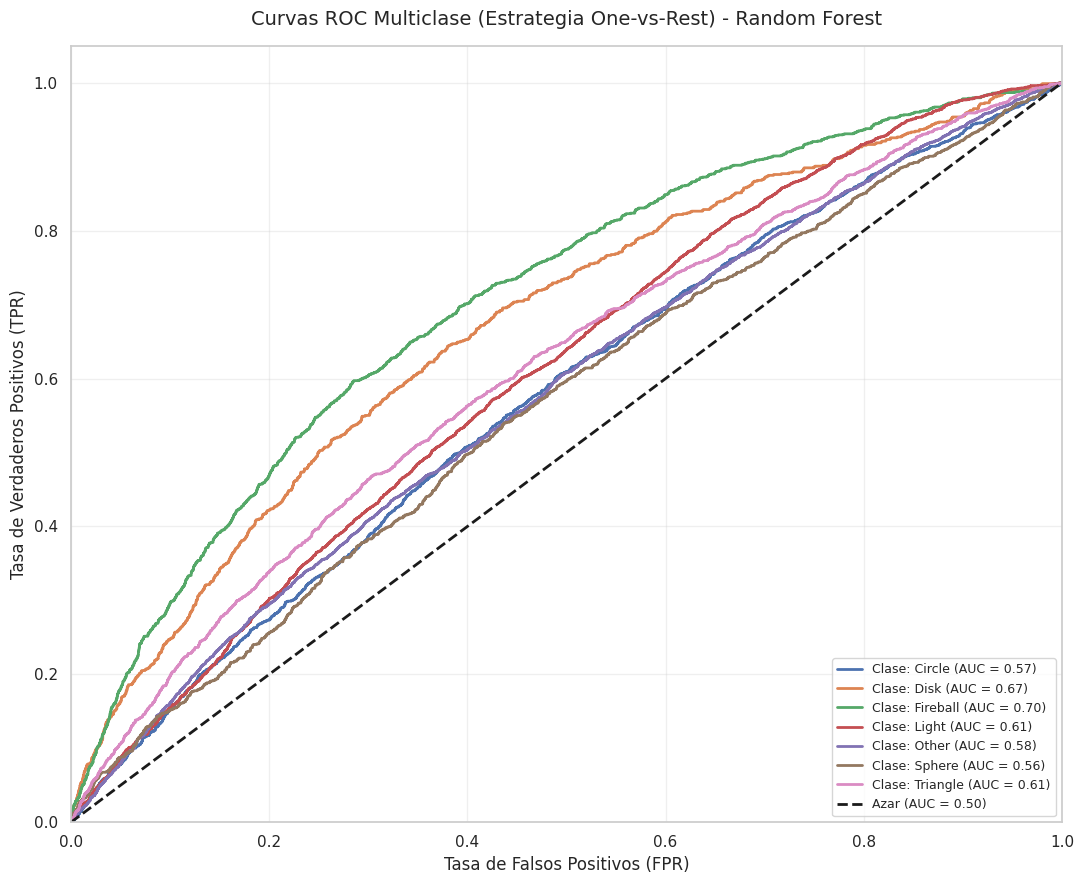

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# 1. Obtener las clases del modelo y binarizar las etiquetas de prueba (y_test)
classes = model_rf.named_steps['classifier'].classes_
n_classes = len(classes)

# Binarización multiclase One-vs-Rest
y_test_bin = label_binarize(y_test, classes=classes)

# Caso de seguridad si por alguna razón detecta 2 clases
if n_classes == 2:
    y_test_bin = np.column_stack([1 - y_test_bin, y_test_bin])

# 2. Obtener las probabilidades predichas para el conjunto de prueba
y_score = model_rf.predict_proba(X_test)

# 3. Calcular la curva ROC y el AUC para cada clase individualmente
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 4. Configurar y generar el gráfico multiclase
plt.figure(figsize=(11, 9))

for i in range(n_classes):
    plt.plot(
        fpr[i], tpr[i],
        lw=2,
        label=f'Clase: {classes[i]} (AUC = {roc_auc[i]:.2f})'
    )

# Línea diagonal de referencia (clasificador aleatorio)
plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Azar (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=12)
plt.title('Curvas ROC Multiclase (Estrategia One-vs-Rest) - Random Forest', fontsize=14, pad=15)
plt.legend(loc='lower right', fontsize=9, frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()

# Guardar imagen en alta resolución y mostrar
plt.savefig('curva_roc_multiclase_rf.png', dpi=300)
plt.show()

### Visualización de la distribución de valores reales y predichos

El gráfico de barras compara la cantidad de registros reales (en azul) frente a la cantidad de registros predichos por el modelo de Random Forest (en naranja) para cada una de las categorías de la variable objetivo.

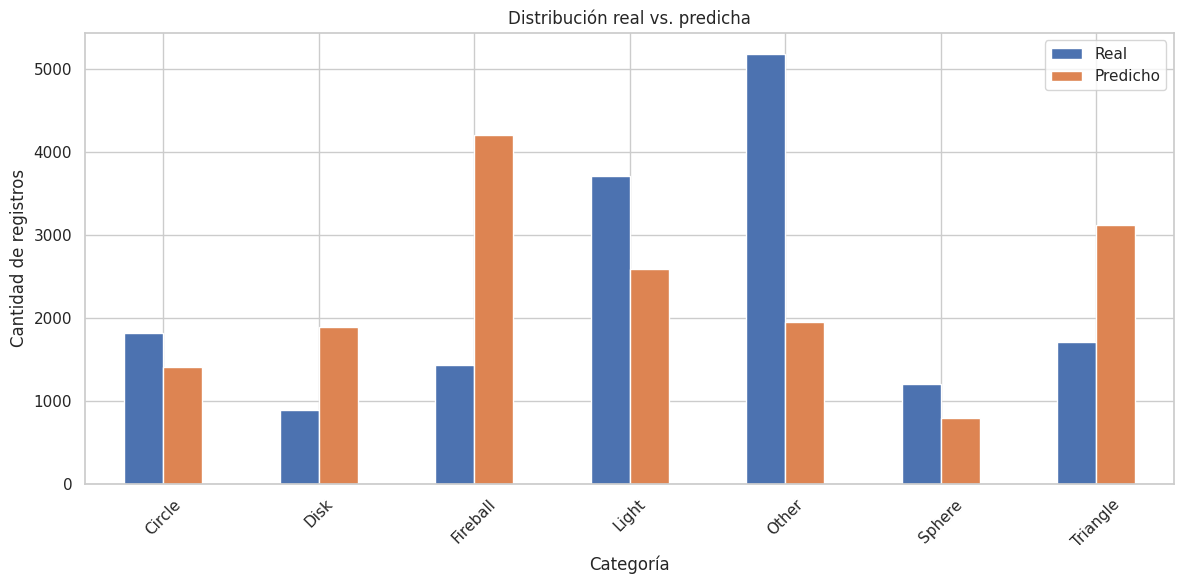

In [12]:
comparacion = pd.DataFrame({
    'Real': pd.Series(y_test).value_counts(),
    'Predicho': pd.Series(y_pred_rf).value_counts()
}).fillna(0)

comparacion.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Distribución real vs. predicha')
plt.ylabel('Cantidad de registros')
plt.xlabel('Categoría')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## EXTRA - SIMULACIÓN DEL MODELO CON NUEVOS DATOS ARTIFICIALES

Se desarrolló un código complementario para simular el funcionamiento del modelo Random Forest utilizando registros con valores artificiales, distintos de los empleados durante el entrenamiento para demostrar cómo el modelo puede recibir nuevos datos de entrada y generar predicciones sobre la categoría de forma (shape_grouped) correspondiente a cada registro.

Esta simulación permite observar la aplicación práctica del modelo en un escenario de uso, mostrando cómo podría utilizarse para clasificar nuevos reportes de avistamientos.

In [13]:
import pandas as pd

# 1. Crear un DataFrame con todos los atributos necesarios que el pipeline espera
nuevos_datos = pd.DataFrame({
    'duration_seconds': [300, 120, 1500],
    'year': [2019, 2020, 2021],
    'month': [10, 11, 12],
    'day_of_week': [4, 5, 6],  # 0=Lunes, 6=Domingo, etc.
    'hour': [22, 2, 15],
    'state_grouped': ['FL', 'IL', 'TX'],
    'us_region': ['South', 'Midwest', 'South'],
    'north_season': ['summer', 'fall', 'winter'],
    'time_of_day': ['noche', 'noche', 'tarde'],
    'day_category': ['Fin de semana', 'Día de semana', 'Fin de semana'],
    'is_weekend': [True, False, True],
    'Duracion_clasificacion': ['Corto', 'Corto', 'Medio'],
    'decade': ['2010s', '2020s', '2020s']
})

# 2. Ejecutar la predicción usando el pipeline entrenado ('model_rf')
predicciones = model_rf.predict(nuevos_datos)

# 3. (Opcional) Ver las probabilidades de cada clase para evaluar la certeza del modelo
probabilidades = model_rf.predict_proba(nuevos_datos)

# Mostrar los resultados
print()
print("RESULTADOS DE LA SIMULACIÓN CON DATOS ARTIFICIALES APLICANDO  -->  Random Forest")
print()
for caso, pred in zip(nuevos_datos.to_dict(orient='records'), predicciones):
    print(f"Contexto: {caso} --> Forma predicha: **{pred}**")
print()


RESULTADOS DE LA SIMULACIÓN CON DATOS ARTIFICIALES APLICANDO  -->  Random Forest

Contexto: {'duration_seconds': 300, 'year': 2019, 'month': 10, 'day_of_week': 4, 'hour': 22, 'state_grouped': 'FL', 'us_region': 'South', 'north_season': 'summer', 'time_of_day': 'noche', 'day_category': 'Fin de semana', 'is_weekend': True, 'Duracion_clasificacion': 'Corto', 'decade': '2010s'} --> Forma predicha: **Circle**
Contexto: {'duration_seconds': 120, 'year': 2020, 'month': 11, 'day_of_week': 5, 'hour': 2, 'state_grouped': 'IL', 'us_region': 'Midwest', 'north_season': 'fall', 'time_of_day': 'noche', 'day_category': 'Día de semana', 'is_weekend': False, 'Duracion_clasificacion': 'Corto', 'decade': '2020s'} --> Forma predicha: **Disk**
Contexto: {'duration_seconds': 1500, 'year': 2021, 'month': 12, 'day_of_week': 6, 'hour': 15, 'state_grouped': 'TX', 'us_region': 'South', 'north_season': 'winter', 'time_of_day': 'tarde', 'day_category': 'Fin de semana', 'is_weekend': True, 'Duracion_clasificacion':

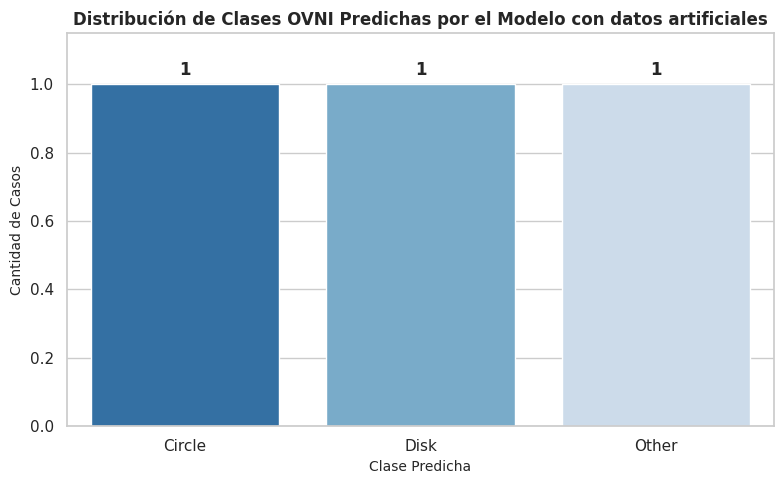

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
# Convertir las predicciones a un DataFrame para facilitar el gráfico
df_resultados = nuevos_datos.copy()
df_resultados['prediccion'] = predicciones

plt.figure(figsize=(8, 5))
sns.set_theme(style='whitegrid')
# Gráfico de conteo de las clases predichas
ax = sns.countplot(
    data=df_resultados, x='prediccion', palette='Blues_r', hue='prediccion', legend=False
)
max_height = max([p.get_height() for p in ax.patches]) if ax.patches else 1
ax.set_ylim(0, max_height * 1.15)

for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f'{int(height)}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        xytext=(0, 4),
        textcoords='offset points',
        fontweight='bold',
    )

plt.title(
    'Distribución de Clases OVNI Predichas por el Modelo con datos artificiales',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Clase Predicha', fontsize=10)
plt.ylabel('Cantidad de Casos', fontsize=10)
plt.tight_layout()
plt.show()


## Conclusiones generales sobre el modelo

En función del objetivo en este proyecto y de los resultados obtenidos mediante el modelo Random Forest con balanceo de clases, los resultados permiten observar que el modelo consigue aprender algunos patrones de los registros históricos, puede reconocer determinadas categorías de forma de OVNI mejor que otras; pero en general tiene grandes dificultades para distinguir las siete categorías de formas definidas en shape_grouped, alcanzando un rendimiento predictivo limitado.

Eso podría estar relacionado a la naturaleza del problema: la forma reportada es una descripción subjetiva del testigo y las variables de contexto (cuándo, dónde, cuánto duró) aportan muy poca información sobre ella.

Por eso dicho modelo no alcanza a predecir con precisión la forma de un objeto volador no identificado a partir de las características temporales, geográficas, de duración de los avistamientos que se presentaron como variables de entrada, pues la forma ( especificadas en shape o shape_grouped) es una percepción del testigo, no una consecuencia de la hora, la estación o el estado donde ocurre. Esas variables describen el contexto, no el objeto.

El modelo alcanzó una accuracy de 21,1 % y un F1 macro de 0,19 sobre siete clases, un desempeño comparable al de una predicción aleatoria. Observando las métricas obtenidas, el “buen” desempeño de Fireball (recall 53 %) podría estar relacionado con el balanceo de clases, su precisión es de sólo 18 %, o sea que el modelo identifica una parte de los casos reales, pero también clasifica incorrectamente como Fireball muchos registros de otras categorías. Lo mismo ocurre con las formas Disc y Triangle. El rendimiento limitado no se debe principalmente a la elección del algoritmo, sino a la baja relación entre las variables predictoras y la variable objetivo.

El rendimiento obtenido indica que todavía existen oportunidades de mejora mediante la experimentación con otros algoritmos y diferentes estrategias de tratamiento de las variables que no implementamos como por ejemplo tomar como variable objetivo 'duration_seconds' como un problema de regresion, también realizar pruebas con modelos de aprendizaje no-supervisados. Otra alternativa que puede quedar como objeto de otra línea de investigación es analizar el texto de los reportes (columna ´summary´ en el dataset original) mediante análisis de texto con modelos NLP (Procesamiento del Lenguaje Natural), que es información importante de estos eventos pero que el modelo actualmente no ve porque no fue considerada dentro del alcance del proyecto; todas estas propuestas quedan delimitadas para otros proyectos en el futuro.


